### Deep learning - Practical session 1.1

## torch.tensor

In [9]:
# Module importation
import torch
import numpy as np

### Creating PyTorch tensors

In [10]:
#Directly from (Python) data
data = [[1, 2],
        [3, 4]]

x_data = torch.tensor(data)
x_data

tensor([[1, 2],
        [3, 4]])

In [11]:
# From a numpy array
np_array = np.array(data)
x_np = torch.from_numpy(np_array)
x_np

tensor([[1, 2],
        [3, 4]])

In [12]:
# From another tensor
x_ones = torch.ones_like(x_data)
x_ones

tensor([[1, 1],
        [1, 1]])

In [13]:
# With random or constant values
shape = (2, 3)
rand_tensor = torch.rand(shape)
ones_tensor = torch.ones(shape)
zeros_tensor = torch.zeros(shape)

print(f"Random Tensor: \n {rand_tensor}")
print(f"Ones Tensor: \n {ones_tensor}")
print(f"Zeros Tensor: \n {zeros_tensor}")

Random Tensor: 
 tensor([[0.7895, 0.7771, 0.0863],
        [0.6118, 0.5514, 0.9909]])
Ones Tensor: 
 tensor([[1., 1., 1.],
        [1., 1., 1.]])
Zeros Tensor: 
 tensor([[0., 0., 0.],
        [0., 0., 0.]])


### Attributes of a PyTorch tensor

Tensor attributes specify their shape, datatype, and the device (e.g, CPU or GPU) on which their data is stored and processed

In [14]:
tensor = torch.rand(2, 2)

print(f"Shape of tensor: {tensor.shape}")
print(f"Device tensor is stored on: {tensor.device}")
print(f"Datatype of tensor: {tensor.dtype}")
print(f"Datatype of x_np: {x_np.dtype}")

Shape of tensor: torch.Size([2, 2])
Device tensor is stored on: cpu
Datatype of tensor: torch.float32
Datatype of x_np: torch.int64


The default dtype of a Tensor is float32, whereas the default dtype of a Numpy array is float64. PyTorch need all the tensors to have the same dtype to perform essential operations

In [15]:
#torch.matmul(tensor, x_np)

This raise an error because the two tensors have different dtype. To fix the error, we can change the data type of a Tensor with the method to()

In [16]:
x_np32 = x_np.to(dtype=torch.float32)
print(f"Before : {x_np.dtype}")
print(f"After : {x_np32.dtype}")

Before : torch.int64
After : torch.float32


In [17]:
torch.matmul(tensor, x_np32)

tensor([[1.3811, 2.0215],
        [1.5697, 2.2909]])

### Operations on tensors

In [18]:
#Move our tensor to the GPU is available
if torch.cuda.is_available():
    tensor = tensor.to("cuda")

In [19]:
# Standard numpy-like indexing and slicing
tensor = torch.ones(4, 4)
print(f"First row: {tensor[0]}")
print(f"First column: {tensor[:, 0]}")
print(f"Last column: {tensor[:, -1]}")
tensor[:, 1] = 0
print(tensor)

First row: tensor([1., 1., 1., 1.])
First column: tensor([1., 1., 1., 1.])
Last column: tensor([1., 1., 1., 1.])
tensor([[1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.]])


In [20]:
# Arithmetic operations

## Matrix multiplication
print(torch.matmul(tensor, tensor.T))
print(tensor.matmul(tensor.T))
print(tensor @ tensor.T)  # Shorter syntax.

#Element-wise multiplication
print(tensor.mul(tensor.T))
print(torch.mul(tensor, tensor.T))
print(tensor * tensor.T)  # Shorter syntax.

tensor([[3., 3., 3., 3.],
        [3., 3., 3., 3.],
        [3., 3., 3., 3.],
        [3., 3., 3., 3.]])
tensor([[3., 3., 3., 3.],
        [3., 3., 3., 3.],
        [3., 3., 3., 3.],
        [3., 3., 3., 3.]])
tensor([[3., 3., 3., 3.],
        [3., 3., 3., 3.],
        [3., 3., 3., 3.],
        [3., 3., 3., 3.]])
tensor([[1., 0., 1., 1.],
        [0., 0., 0., 0.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.]])
tensor([[1., 0., 1., 1.],
        [0., 0., 0., 0.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.]])
tensor([[1., 0., 1., 1.],
        [0., 0., 0., 0.],
        [1., 0., 1., 1.],
        [1., 0., 1., 1.]])


In [21]:
#Single-element tensors
result_sum = tensor.sum()
result_sum_item = result_sum.item()
print(f'{result_sum=},\t {type(result_sum)=}')
print(f'{result_sum_item=},\t {type(result_sum_item)=}')

result_sum=tensor(12.),	 type(result_sum)=<class 'torch.Tensor'>
result_sum_item=12.0,	 type(result_sum_item)=<class 'float'>


### Datasets and Dataloaders

#### Loading a commonly used Dataset

In [22]:
%pip install torchvision

from torchvision import datasets
from torchvision.transforms import ToTensor


training_data = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=ToTensor()
)

test_data = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=ToTensor()
)

Note: you may need to restart the kernel to use updated packages.


c:\Users\EliteBook\Documents\3A\Deep_learning\practice\deep_learning_practice\.venv\Scripts\python.exe: No module named pip


In [23]:
from torch.utils.data import random_split

training_data, validation_data = random_split(training_data, [50_000, 10_000])

#### Iterating and visualizing the Dataset

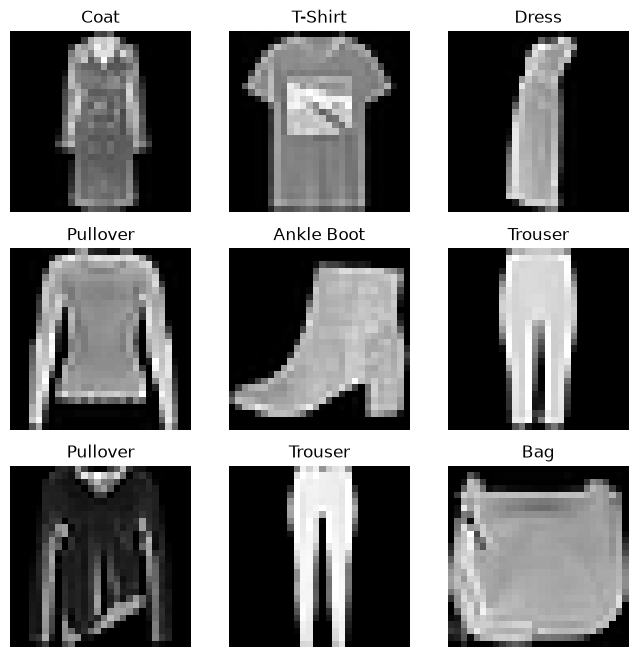

In [24]:
import matplotlib.pyplot as plt

labels_map = {
    0: "T-Shirt",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle Boot",
}

figure = plt.figure(figsize=(8, 8))
cols, rows = 3, 3
for i in range(1, cols * rows + 1):
    sample_idx = torch.randint(len(training_data), size=(1,)).item()
    img, label = training_data[sample_idx]
    figure.add_subplot(rows, cols, i)
    plt.title(labels_map[label])
    plt.axis("off")
    plt.imshow(img.squeeze(), cmap="gray")
plt.show()

#### Creating a custom Dataset

In [25]:
%pip install pandas

import os 
import pandas as pd
from torchvision.io import read_image
from torch.utils.data import Dataset

class CustomImageDataset(Dataset):
    def __init__(self, annotations_file, img_dir, 
                 transform = None, target_transform = None):
        self.img_labels = pd.read_csv(annotations_file)
        self.img_dir = img_dir
        self.transform = transform
        self.target_transform = target_transform
        
    def __len__(self):
        return len(self.img_labels)
    
    def __getitem__(self, idx):
        img_path = os.path.join(self.img_dir, 
                                self.img_lables.iloc[idx, 0])
        image = read_image(img_path)
        label = self.img_labels.iloc[idx, 1]
        if self.transform:
            image = self.transform(image)
        if self.target_transform:
            label = self.target_transform(label)
        return image, label

c:\Users\EliteBook\Documents\3A\Deep_learning\practice\deep_learning_practice\.venv\Scripts\python.exe: No module named pip


Note: you may need to restart the kernel to use updated packages.


#### Preparing your data for training with DataLoader

In [26]:
from torch.utils.data import DataLoader

train_dataloader = DataLoader(training_data, batch_size = 64, shuffle = True)
validation_dataloader = DataLoader(validation_data, batch_size = 64, shuffle = False)
test_dataloader = DataLoader(test_data, batch_size = 64, shuffle = False)

#### Iterate through the DataLoader

Feature batch shape: torch.Size([64, 1, 28, 28])
Labels batch shape: torch.Size([64])


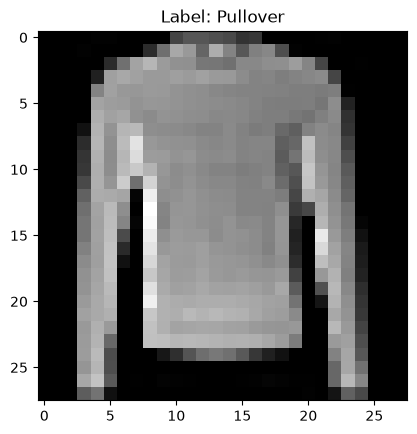

In [27]:
for imgs, labels in train_dataloader:
    print(f"Feature batch shape: {imgs.size()}")
    print(f"Labels batch shape: {labels.size()}")
    for img, label in zip(imgs, labels):
        plt.imshow(img.squeeze(), cmap="gray")
        plt.title(f"Label: {labels_map[label.item()]}")
        plt.show()
        break
    break

### Building a neural network 

#### Get device for training

In [28]:
device = (
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)
print(f"Using {device} device")

Using cpu device


#### Define the class (the architecture)

In [29]:
from torch import nn

class MyNeuralNet(nn.Module):
    def __init__(self):
        super().__init__()
        
        self.flatten = nn.Flatten()
        self.linear1 = nn.Linear(28*28, 512)
        self.relu1 = nn.ReLU()
        self.linear2 = nn.Linear(512, 512)
        self.relu2 = nn.ReLU()
        self.linear3 = nn.Linear(512, 10)
        
    def forward(self, x):
        y = self.flatten(x)
        y = self.linear1(y)
        y = self.relu1(y)
        y = self.linear2(y)
        y = self.relu2(y)
        y = self.linear3(y)
        return y
        

##### Simplification

In [30]:
class MyNeuralNetSimple1(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.linear_relu_stack = nn.Sequential(
            nn.Linear(28 * 28, 512),
            nn.ReLU(),
            nn.Linear(512, 512),
            nn.ReLU(),
            nn.Linear(512, 10),
        )
        
    def forward(self, x):
        x = self.flatten(x)
        logits = self.linear_relu_stack(x)
        return logits

##### Simplification 2

In [31]:
class MyNeuralNetSimple2(nn.Sequential):
    def __init__(self):
        super().__init__(
            nn.Flatten(),
            nn.Linear(28 * 28, 512),
            nn.ReLU(),
            nn.Linear(512, 512),
            nn.ReLU(),
            nn.Linear(512, 10),
        )

In [32]:
model = MyNeuralNetSimple2().to(device)

In [33]:
print(model)

MyNeuralNetSimple2(
  (0): Flatten(start_dim=1, end_dim=-1)
  (1): Linear(in_features=784, out_features=512, bias=True)
  (2): ReLU()
  (3): Linear(in_features=512, out_features=512, bias=True)
  (4): ReLU()
  (5): Linear(in_features=512, out_features=10, bias=True)
)


In [34]:
%pip install torchinfo

from torchinfo import summary

print(summary(model, input_size = (3, 1, 28, 28)))

Note: you may need to restart the kernel to use updated packages.
Layer (type:depth-idx)                   Output Shape              Param #
MyNeuralNetSimple2                       [3, 10]                   --
├─Flatten: 1-1                           [3, 784]                  --
├─Linear: 1-2                            [3, 512]                  401,920
├─ReLU: 1-3                              [3, 512]                  --
├─Linear: 1-4                            [3, 512]                  262,656
├─ReLU: 1-5                              [3, 512]                  --
├─Linear: 1-6                            [3, 10]                   5,130
Total params: 669,706
Trainable params: 669,706
Non-trainable params: 0
Total mult-adds (Units.MEGABYTES): 2.01
Input size (MB): 0.01
Forward/backward pass size (MB): 0.02
Params size (MB): 2.68
Estimated Total Size (MB): 2.71


c:\Users\EliteBook\Documents\3A\Deep_learning\practice\deep_learning_practice\.venv\Scripts\python.exe: No module named pip


Logits: tensor([[ 2.6715e-02, -3.2761e-02, -7.7233e-02,  1.2710e-02,  8.4141e-05,
          3.9405e-02,  2.8661e-03, -9.8133e-03,  3.0628e-02, -7.4446e-02]],
       grad_fn=<AddmmBackward0>)
Predicted probabilities: tensor([[0.1035, 0.0975, 0.0933, 0.1020, 0.1008, 0.1048, 0.1010, 0.0998, 0.1039,
         0.0935]], grad_fn=<SoftmaxBackward0>)
True label: Ankle Boot
Predicted class: Sandal


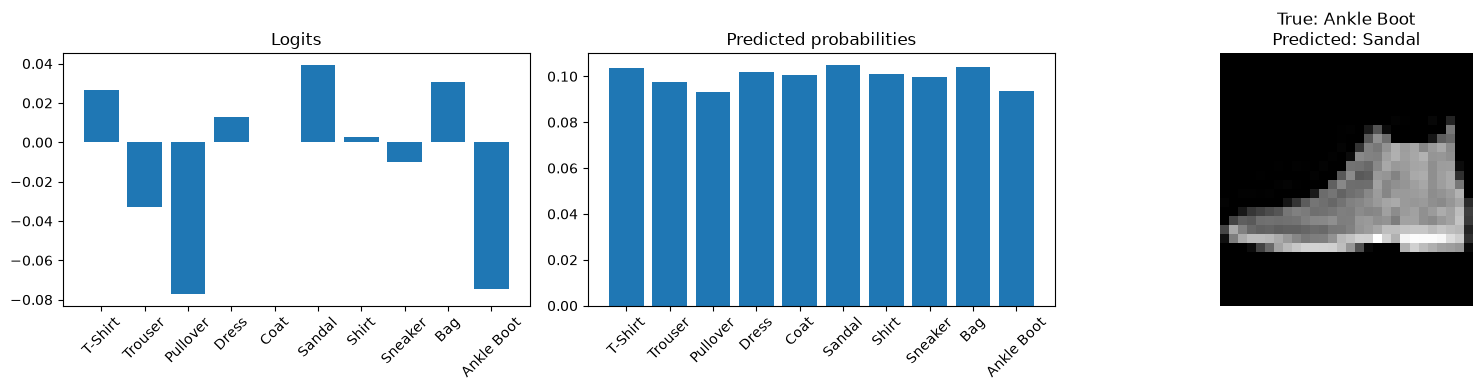

In [35]:
def plot_prediction(model, image, true_label):
    """Show an image next to bar charts of the model's logits and predicted probabilities."""
    X = image.unsqueeze(0).to(device)
    logits = model(X)
    pred_probab = nn.Softmax(dim = 1)(logits)
    y_pred = pred_probab.argmax(1)
    
    print(f"Logits: {logits}")
    print(f"Predicted probabilities: {pred_probab}")
    print(f"True label: {labels_map[true_label]}")
    print(f"Predicted class: {labels_map[y_pred.item()]}")
    
    class_names = [labels_map[i] for i in range(len(labels_map))]
    fig, (ax_logits, ax_probs, ax_img) = plt.subplots(1, 3, figsize=(16, 4))

    ax_img.imshow(X.detach().cpu().squeeze(), cmap="gray")
    ax_img.set_title(f"True: {labels_map[true_label]}\nPredicted: {labels_map[y_pred.item()]}")
    ax_img.axis("off")

    ax_logits.bar(class_names, logits.detach().cpu().numpy().flatten())
    ax_logits.set_title("Logits")
    ax_logits.tick_params(axis="x", rotation=45)

    ax_probs.bar(class_names, pred_probab.detach().cpu().numpy().flatten())
    ax_probs.set_title("Predicted probabilities")
    ax_probs.tick_params(axis="x", rotation=45)

    plt.tight_layout()
    plt.show()
    
example_image, example_label = test_data[0]
plot_prediction(model, example_image, example_label)

#### Model parameters

In [36]:
for name, param in model.named_parameters():
    print(f"Layer: {name} | Size: {param.size()} | Values: {param[:2]} \n")

Layer: 1.weight | Size: torch.Size([512, 784]) | Values: tensor([[-0.0290, -0.0158,  0.0256,  ..., -0.0018, -0.0199, -0.0013],
        [ 0.0002,  0.0010, -0.0179,  ..., -0.0138, -0.0235,  0.0339]],
       grad_fn=<SliceBackward0>) 

Layer: 1.bias | Size: torch.Size([512]) | Values: tensor([ 0.0131, -0.0027], grad_fn=<SliceBackward0>) 

Layer: 3.weight | Size: torch.Size([512, 512]) | Values: tensor([[-0.0267,  0.0346,  0.0403,  ...,  0.0202, -0.0424, -0.0185],
        [ 0.0370,  0.0211, -0.0165,  ..., -0.0049, -0.0053,  0.0013]],
       grad_fn=<SliceBackward0>) 

Layer: 3.bias | Size: torch.Size([512]) | Values: tensor([0.0078, 0.0350], grad_fn=<SliceBackward0>) 

Layer: 5.weight | Size: torch.Size([10, 512]) | Values: tensor([[-0.0041, -0.0317,  0.0126,  ...,  0.0401, -0.0323,  0.0062],
        [ 0.0385,  0.0147,  0.0108,  ...,  0.0111,  0.0177, -0.0041]],
       grad_fn=<SliceBackward0>) 

Layer: 5.bias | Size: torch.Size([10]) | Values: tensor([ 0.0431, -0.0104], grad_fn=<SliceBack

#### Hyperparameters

In [37]:
learning_rate = 1e-3
batch_size = 64
epochs = 10

#### Optimization Loop

In [38]:
loss_fn_mean = nn.CrossEntropyLoss(reduction='mean')
loss_fn_sum = nn.CrossEntropyLoss(reduction='sum')

In [39]:
optimizer = torch.optim.SGD(model.parameters(), lr = learning_rate)

In [49]:
def training_step(model, batch, loss_fn, optimizer, device):
    """Performs one optimization step on a single batch, and returns the loss."""
    X, y = batch
    X = X.to(device)
    y = y.to(device)
    
    pred = model(X)
    loss = loss_fn(pred, y)
    
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    
    return loss.item()

def validation_step(model, batch, loss_fn, device):
    """Evaluates the model on a single batch, and returns the loss and the
    number of correct predictions."""
    X, y = batch
    X = X.to(device)
    y = y.to(device)
    
    with torch.no_grad():
        pred = model(X)
        loss = loss_fn(pred, y).item()
        correct = (pred.argmax(1) == y).type(torch.float).sum().item()
        
    return loss, correct

def fit(model, train_dataloader, validation_dataloader, loss_fn_mean, loss_fn_sum, optimizer, device, n_epochs=5):
    """Trains the model for n_epochs, periodically printing the training loss,
    and the validation loss and accuracy after each epoch."""
    train_size = len(train_dataloader.dataset)
    size = len(validation_dataloader.dataset)
    
    for epoch in range(n_epochs):
        print('-------------------------------')
        print(f"Epoch {epoch + 1}")
        
        model.train()
        for batch_idx, batch in enumerate(train_dataloader):
            loss = training_step(model, batch, loss_fn_mean, optimizer, device)
            
            if batch_idx % 100 == 0:
                X, y = batch
                current = (batch_idx + 1) * len(X)
                print(f"Training loss (mini-batch avg.)={loss: >7f}  [{current: >5d} / {train_size: >5d}]")
                
        model.eval()
        validation_loss, correct = 0, 0
        for batch in validation_dataloader:
            loss, n_correct = validation_step(model, batch, loss_fn_sum, device)
            validation_loss += loss
            correct += n_correct
        validation_loss /= size
        correct /= size
        print(f"Validation loss (full-batch avg.)={validation_loss: >8f}")
        print(f"Validation accuracy (full-batch avg.)={(100 * correct): >0.1f}%")
        
    print("Done!")
        
        

-------------------------------
Epoch 1
Training loss (mini-batch avg.)=1.429504  [   64 / 50000]
Training loss (mini-batch avg.)=1.455245  [ 6464 / 50000]
Training loss (mini-batch avg.)=1.290300  [12864 / 50000]
Training loss (mini-batch avg.)=1.308183  [19264 / 50000]
Training loss (mini-batch avg.)=1.384593  [25664 / 50000]
Training loss (mini-batch avg.)=1.262501  [32064 / 50000]
Training loss (mini-batch avg.)=1.153714  [38464 / 50000]
Training loss (mini-batch avg.)=1.190921  [44864 / 50000]
Validation loss (full-batch avg.)=1.198887
Validation accuracy (full-batch avg.)=66.2%
-------------------------------
Epoch 2
Training loss (mini-batch avg.)=1.220455  [   64 / 50000]
Training loss (mini-batch avg.)=1.222063  [ 6464 / 50000]
Training loss (mini-batch avg.)=1.037456  [12864 / 50000]
Training loss (mini-batch avg.)=1.264162  [19264 / 50000]
Training loss (mini-batch avg.)=1.097836  [25664 / 50000]
Training loss (mini-batch avg.)=1.107022  [32064 / 50000]
Training loss (mini-b

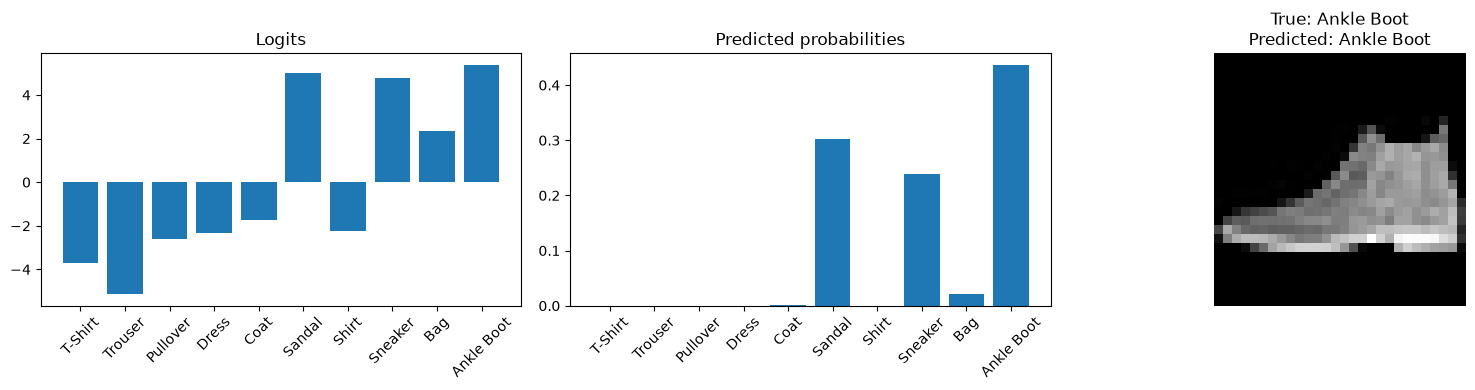

In [50]:
fit(model, train_dataloader, validation_dataloader, loss_fn_mean, loss_fn_sum, optimizer, device, n_epochs=10)
plot_prediction(model, example_image, example_label)

#### Tracking training loss curve

In [51]:
%pip install tqdm

Note: you may need to restart the kernel to use updated packages.


c:\Users\EliteBook\Documents\3A\Deep_learning\practice\deep_learning_practice\.venv\Scripts\python.exe: No module named pip


In [53]:
from IPython.display import display, clear_output
from matplotlib.ticker import MaxNLocator
from tqdm.auto import tqdm


# Not the focus of this notebook: skim the plotting code below if you like.
class LiveLossPlot():
    """Refreshes a matplotlib plot of the training and validation loss in
    place, once per epoch."""

    def __init__(self):
        self.epochs = []
        self.train_losses = []
        self.val_losses = []
        self.fig, self.ax = plt.subplots(figsize=(6, 4))

    def update(self, epoch, train_loss, val_loss):
        self.epochs.append(epoch)
        self.train_losses.append(train_loss)
        self.val_losses.append(val_loss)

        self.ax.clear()
        self.ax.plot(self.epochs, self.train_losses, label="Train")
        self.ax.plot(self.epochs, self.val_losses, label="Val")
        self.ax.set_xlabel("Epoch")
        self.ax.set_ylabel("Loss")
        self.ax.xaxis.set_major_locator(MaxNLocator(integer=True))
        self.ax.legend()

        clear_output(wait=True)
        display(self.fig)

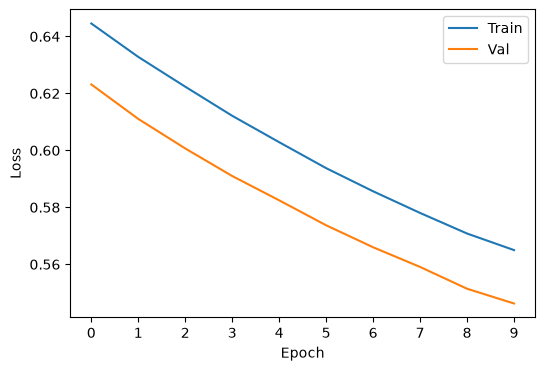

Finished Training!


In [55]:
def fit(model, train_dataloader, validation_dataloader, loss_fn_mean, loss_fn_sum, optimizer, device, epochs=5):
    """Trains the model for epochs, updating a live plot of the training and validation loss."""
    # Same train-then-validate structure as fit() above, but with a live plot
    # and a tqdm progress bar instead of periodic print statements.
    validation_size = len(validation_dataloader.dataset)
    plotter = LiveLossPlot()

    for epoch in range(epochs):
        model.train()

        pbar = tqdm(train_dataloader, desc=f'Epoch {epoch}')  # Progress bar
        running_loss, n_batches = 0.0, 0
        for batch in pbar:
            loss = training_step(model, batch, loss_fn_mean, optimizer, device)
            pbar.set_postfix(loss=f'{loss:.4f}')
            running_loss += loss
            n_batches += 1
        train_loss = running_loss / n_batches

        model.eval()
        validation_loss = 0
        for batch in validation_dataloader:
            loss, _ = validation_step(model, batch, loss_fn_sum, device)
            validation_loss += loss
        validation_loss /= validation_size

        plotter.update(epoch, train_loss, validation_loss)

    plt.close(plotter.fig)
    print("Finished Training!")


fit(model, train_dataloader, validation_dataloader, loss_fn_mean, loss_fn_sum, optimizer, device, epochs=10)

#### Organizing Components into Python Classes

In [56]:
class MyTrainableModel(MyNeuralNet):
    def __init__(self, loss_fn_mean, loss_fn_sum):
        super().__init__()
        self.loss_fn_mean = loss_fn_mean
        self.loss_fn_sum = loss_fn_sum

    def configure_optimizers(self):
        return torch.optim.SGD(self.parameters(), lr=1e-3)

    def training_step(self, batch):
        X, y = batch
        pred = self(X)
        return self.loss_fn_mean(pred, y)

    def validation_step(self, batch):
        X, y = batch
        with torch.no_grad():
            pred = self(X)
            loss = self.loss_fn_sum(pred, y).item()
        return loss, pred.argmax(1), y

In [57]:
class MyTrainer():
    def __init__(self, max_epochs, device):
        self.max_epochs = max_epochs
        self.device = device

    def fit(self, model, train_dataloader, validation_dataloader):
        # Same structure as fit() above: train, then validate, then update the
        # plot, each epoch. The difference: training_step/validation_step/
        # configure_optimizers are now looked up on the model itself, instead
        # of being passed in as separate arguments.
        model = model.to(self.device)
        optimizer = model.configure_optimizers()
        plotter = LiveLossPlot()

        for epoch in range(self.max_epochs):
            model.train()

            pbar = tqdm(train_dataloader, desc=f'Epoch {epoch}')
            running_loss, n_batches = 0.0, 0
            for X, y in pbar:
                X = X.to(self.device)
                y = y.to(self.device)
                loss = model.training_step((X, y))

                optimizer.zero_grad()
                loss.backward()
                optimizer.step()

                pbar.set_postfix(loss=f'{loss.item():.4f}')
                running_loss += loss.item()
                n_batches += 1
            train_loss = running_loss / n_batches

            model.eval()
            validation_size = len(validation_dataloader.dataset)
            validation_loss = 0
            for X, y in validation_dataloader:
                X = X.to(self.device)
                y = y.to(self.device)
                loss, pred, y_true = model.validation_step((X, y))
                validation_loss += loss
            validation_loss /= validation_size

            plotter.update(epoch, train_loss, validation_loss)

        plt.close(plotter.fig)
        print("Finished Training!")

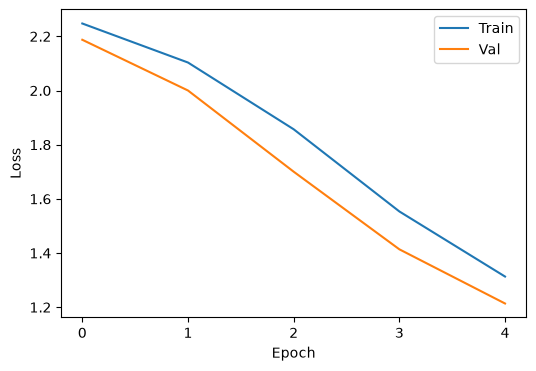

Finished Training!


In [58]:
model_live = MyTrainableModel(
    loss_fn_mean=nn.CrossEntropyLoss(reduction='mean'),
    loss_fn_sum=nn.CrossEntropyLoss(reduction='sum'),
)

trainer_live = MyTrainer(max_epochs=5, device=device)
trainer_live.fit(model_live, train_dataloader, validation_dataloader)